# 02. Biểu diễn dữ liệu và hàm mất mát (Bước 2 và 3)

**Nhiệm vụ của notebook này:** biến sinh viên thành vector, ma trận, rồi đo mức phạt khi đoán sai (mục 2.3, 2.4).

Chạy từng ô từ trên xuống. Notebook tự đọc `data.csv` (Colab sẽ hỏi bạn tải lên; trên máy thì đặt tại `data/data.csv`).

Nên đọc theo thứ tự các notebook 01 → 06. Phần trước: 01.

In [1]:
# Ô thiết lập: cài thư viện (nếu thiếu), nạp thư viện và đọc dữ liệu
# Cài thư viện còn thiếu (tự động). Chạy được cả trên máy cá nhân lẫn Google Colab.
import importlib.util, subprocess, sys
_can = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib", "sklearn": "scikit-learn"}
_thieu = [g for m, g in _can.items() if importlib.util.find_spec(m) is None]
if _thieu:
    print("Máy chưa có:", ", ".join(_thieu), "-> đang cài, đợi một chút ...")
    if importlib.util.find_spec("pip") is None:      # môi trường ảo (venv) có thể chưa có pip
        import ensurepip; ensurepip.bootstrap()
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_thieu])
    importlib.invalidate_caches()
    print("Cài xong.")

import io, os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

warnings.filterwarnings("ignore")
SEED = 42                               # hạt giống ngẫu nhiên cố định: chạy lại ra đúng kết quả cũ
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def doc_du_lieu():
    """Tìm data.csv trên máy; nếu đang ở Colab thì xin người dùng tải lên."""
    for p in ["data/data.csv", "../data/data.csv", "../../data/data.csv", "data.csv"]:
        if os.path.exists(p):
            print("Đọc dữ liệu từ", p)
            return pd.read_csv(p, sep=";")
    try:
        from google.colab import files
        print("Hãy chọn tệp data.csv trên máy của bạn ...")
        up = files.upload()
        return pd.read_csv(io.BytesIO(list(up.values())[0]), sep=";")
    except ImportError:
        raise FileNotFoundError(f"Không thấy data.csv (thư mục hiện tại: {os.getcwd()}). Hãy đặt tệp vào thư mục data/ của dự án.")


raw = doc_du_lieu()
raw.columns = [c.strip() for c in raw.columns]      # bỏ khoảng trắng/tab thừa ở tên cột
print("Kích thước:", raw.shape)

# --- Chuẩn bị chung (lặp lại ở mỗi notebook để mỗi tệp chạy độc lập) ---
d = raw[raw.Target != "Enrolled"].reset_index(drop=True)
d["y"] = (d.Target == "Dropout").astype(int)          # 1 = bỏ học (nguy cơ), 0 = tốt nghiệp (an toàn)
ENTRY = ["Tuition fees up to date", "Debtor", "Scholarship holder", "Age at enrollment"]
YEAR1 = ["Curricular units 1st sem (approved)", "Curricular units 1st sem (grade)",
         "Curricular units 2nd sem (approved)", "Curricular units 2nd sem (grade)"]
COMPACT = ENTRY + YEAR1
ADMISSION_ONLY = ["Admission grade", "Previous qualification (grade)", "Age at enrollment",
                  "Scholarship holder", "Debtor", "Tuition fees up to date", "Gender", "Application order"]
ALL = [c for c in d.columns if c not in ("Target", "y")]
y = d.y.values
train_idx, test_idx = train_test_split(np.arange(len(d)), test_size=0.2, stratify=d.y, random_state=SEED)
ytr, yte = y[train_idx], y[test_idx]


def chuan_bi(cols, chuan_hoa=True):
    """Ma trận X cho tập huấn luyện và kiểm tra; chuẩn hóa bằng trung bình, độ lệch chuẩn của TẬP HUẤN LUYỆN."""
    X = d[cols].values.astype(float)
    Xtr, Xte = X[train_idx], X[test_idx]
    if chuan_hoa:
        mu, sd = Xtr.mean(0), Xtr.std(0); sd[sd == 0] = 1
        Xtr, Xte = (Xtr - mu) / sd, (Xte - mu) / sd
    return Xtr, Xte


def hoi_quy_sklearn(X, y):
    try:
        return LogisticRegression(penalty=None, max_iter=5000).fit(X, y)
    except Exception:
        return LogisticRegression(C=np.inf, max_iter=5000).fit(X, y)


Đọc dữ liệu từ ../data/data.csv
Kích thước: (4424, 37)


---
# Bước 2. Biến sinh viên thành số (mục 2.3 của đề: đại số tuyến tính)

## Vì sao cần bước này
Máy không hiểu câu "em An hay nghỉ học và nợ học phí". Nó chỉ hiểu số. Nên việc đầu tiên là **viết mỗi sinh viên thành một dãy số**.

## Ba ý chính
1. **Vector.** Một sinh viên là dãy 8 số theo thứ tự cố định (học phí, nợ, học bổng, tuổi, môn qua và điểm hai học kỳ). Đó là một điểm trong không gian 8 chiều.
2. **Ma trận.** Xếp mọi sinh viên chồng lên nhau: mỗi hàng là một em, mỗi cột là một chỉ số. Mọi tính toán sau này chỉ là nhân ma trận.
3. **Tích vô hướng.** Các chỉ số không nặng nhẹ như nhau. Cách tự nhiên để gộp là nhân mỗi chỉ số với một **trọng số** rồi cộng lại thành một "mức nguy hiểm" z. Phép "nhân từng cặp rồi cộng" chính là tích vô hướng. Trọng số lớn nghĩa là chỉ số đó nặng ký; dấu của nó cho biết đẩy nguy cơ lên hay xuống.

**Chuẩn hóa.** Tuổi chạy từ 17 đến 70, còn "đã đóng học phí" chỉ là 0 hoặc 1. Nếu để nguyên, tuổi sẽ lấn át chỉ vì số của nó to, chứ không vì nó quan trọng hơn. Ta đưa mỗi cột về cùng thang: trừ trung bình, chia độ lệch chuẩn (z-score). *Trung bình và độ lệch chuẩn chỉ được tính trên tập huấn luyện*, nên ta chia dữ liệu ngay bây giờ (vì sao phải chia thì thầy giảng kỹ ở Bước 5).

In [2]:
# Chia dữ liệu 80/20, giữ nguyên tỉ lệ nhãn, seed cố định (giải thích kỹ ở Bước 5)
train_idx, test_idx = train_test_split(np.arange(len(d)), test_size=0.2, stratify=d.y, random_state=SEED)
y = d.y.values
ytr, yte = y[train_idx], y[test_idx]
print(f"Huấn luyện: {len(train_idx)} em ({ytr.mean():.2%} bỏ học). Kiểm tra: {len(test_idx)} em ({yte.mean():.2%} bỏ học)")


def chuan_bi(cols, chuan_hoa=True):
    """Trả về ma trận X cho tập huấn luyện và kiểm tra. Chuẩn hóa dùng trung bình và độ lệch chuẩn của TẬP HUẤN LUYỆN."""
    X = d[cols].values.astype(float)
    Xtr, Xte = X[train_idx], X[test_idx]
    if chuan_hoa:
        mu, sd = Xtr.mean(0), Xtr.std(0)
        sd[sd == 0] = 1
        Xtr, Xte = (Xtr - mu) / sd, (Xte - mu) / sd
    return Xtr, Xte


# Một sinh viên là một vector; cả tập là một ma trận
Xtr_raw, _ = chuan_bi(COMPACT, chuan_hoa=False)
Xtr, Xte = chuan_bi(COMPACT, chuan_hoa=True)
print("Ma trận huấn luyện X có kích thước", Xtr.shape, "(số sinh viên × số chỉ số)")
print("\nSinh viên số 0, trước chuẩn hóa:", Xtr_raw[0].round(2))
print("Sinh viên số 0, sau  chuẩn hóa:", Xtr[0].round(2))

Huấn luyện: 2904 em (39.15% bỏ học). Kiểm tra: 726 em (39.12% bỏ học)
Ma trận huấn luyện X có kích thước (2904, 8) (số sinh viên × số chỉ số)

Sinh viên số 0, trước chuẩn hóa: [ 1.  0.  0. 61.  0.  0.  0.  0.]
Sinh viên số 0, sau  chuẩn hóa: [ 0.39 -0.36 -0.61  4.78 -1.5  -2.11 -1.45 -1.85]


In [3]:
# Tích vô hướng: gộp 8 chỉ số thành một "mức nguy hiểm" z = w·x + b
# Trọng số dưới đây là TỰ LẬP chỉ để minh họa (mô hình thật sẽ tự học ở Bước 4)
ten = ["đóng học phí", "nợ", "học bổng", "tuổi", "môn qua HK1", "điểm HK1", "môn qua HK2", "điểm HK2"]
w = np.array([-1.0, 0.5, -0.5, 0.3, -0.4, -0.2, -1.0, -0.3])
b = -0.5

x = Xtr[0]
z = float(np.dot(w, x) + b)                      # đúng bằng w1*x1 + w2*x2 + ... + w8*x8 + b
print("Từng số hạng w_j * x_j:")
for t, wj, xj in zip(ten, w, x):
    print(f"  {t:>14}: {wj:+.1f} × {xj:+.2f} = {wj * xj:+.2f}")
print(f"Cộng lại cộng b: z = {z:+.3f}")

# Cả lớp trong một dòng: nhân ma trận với vector
z_ca_lop = Xtr @ w + b
print("\nMức nguy hiểm của 5 sinh viên đầu:", z_ca_lop[:5].round(2))

Từng số hạng w_j * x_j:
    đóng học phí: -1.0 × +0.39 = -0.39
              nợ: +0.5 × -0.36 = -0.18
        học bổng: -0.5 × -0.61 = +0.31
            tuổi: +0.3 × +4.78 = +1.43
     môn qua HK1: -0.4 × -1.50 = +0.60
        điểm HK1: -0.2 × -2.11 = +0.42
     môn qua HK2: -1.0 × -1.45 = +1.45
        điểm HK2: -0.3 × -1.85 = +0.55
Cộng lại cộng b: z = +3.698

Mức nguy hiểm của 5 sinh viên đầu: [ 3.7   5.05 -0.76  0.55 -1.11]


In [4]:
# Vì sao chuẩn hóa quan trọng? Đo bằng "số điều kiện" của ma trận X^T X / n (liên hệ trị riêng)
def so_dieu_kien(X):
    A = np.hstack([X, np.ones((len(X), 1))])               # thêm cột 1 cho hệ số chặn b
    ev = np.linalg.eigvalsh(A.T @ A / len(A))               # trị riêng
    L = 0.25 * ev.max()                                      # độ "dốc" tối đa của hàm mất mát logistic
    return ev.max(), ev.min(), ev.max() / ev.min(), 2 / L


for ten_cau_hinh, X in [("Có chuẩn hóa", Xtr), ("Không chuẩn hóa", Xtr_raw)]:
    lmax, lmin, cond, lr_max = so_dieu_kien(X)
    print(f"{ten_cau_hinh:>16}: trị riêng lớn nhất {lmax:8.1f}, số điều kiện {cond:9.1f}, tốc độ học an toàn tối đa ≈ {lr_max:.4f}")

    Có chuẩn hóa: trị riêng lớn nhất      3.7, số điều kiện      66.7, tốc độ học an toàn tối đa ≈ 2.1725
 Không chuẩn hóa: trị riêng lớn nhất    861.7, số điều kiện   30621.8, tốc độ học an toàn tối đa ≈ 0.0093


## Đọc kết quả
- Sinh viên giờ là một vector 8 chiều, cả tập huấn luyện là một ma trận cỡ 2904 × 8.
- "Mức nguy hiểm" chỉ là tổng của tám số hạng. Dòng `Xtr @ w + b` tính cho cả lớp trong một lần: đó là lý do máy tính xử lý rất nhanh.
- **Số điều kiện** là tỉ số giữa trị riêng lớn nhất và nhỏ nhất. Nó cho biết "bề mặt" hàm mất mát bị méo đến đâu. Không chuẩn hóa thì số này lên tới hàng chục nghìn và tốc độ học an toàn chỉ cỡ 0,009; chuẩn hóa thì số điều kiện chỉ khoảng 67 và tốc độ học an toàn lên tới khoảng 2. Ở Bước 4 ta sẽ thấy thí nghiệm khớp đúng điều này.
- **Không dùng PCA hay SVD.** Mô hình ở đây không cần giảm chiều và chỉ có tám đặc trưng. Đề cho phép nêu rõ phần toán nào không dùng.

## Thầy có thể hỏi
- *Vì sao phải chuẩn hóa?* Để các cột cùng thang đo, và quan trọng hơn: để Gradient Descent hội tụ nhanh và ổn định (số điều kiện nhỏ).
- *Vì sao chỉ tính trung bình và độ lệch chuẩn trên tập huấn luyện?* Nếu tính cả trên tập kiểm tra thì thông tin của tập kiểm tra rò vào lúc huấn luyện (rò rỉ dữ liệu) và điểm đánh giá bị đẹp giả.
- *Tích vô hướng nghĩa là gì?* Nhân từng cặp chỉ số với trọng số rồi cộng: một cách "bỏ phiếu có trọng số" của các chỉ số.

---
# Bước 3. Từ mức nguy hiểm đến xác suất, và hàm mất mát (mục 2.4 của đề: giải tích)

## Vì sao cần bước này
Hai câu hỏi liên tiếp:
1. Mức nguy hiểm z có thể là -5 hay 37, khó đọc. Giáo viên muốn nghe "em này có 80% khả năng bỏ học". Làm sao đổi z thành xác suất?
2. Mô hình đoán sai đến mức nào? Cần một con số đo nỗi "đau" của việc đoán sai để còn biết sửa.

## Ý chính
**Sigmoid** nén mọi số thực về khoảng từ 0 đến 1: z rất âm cho xác suất gần 0, z bằng 0 cho đúng 0,5, z rất dương cho xác suất gần 1. Kết quả p là *xác suất có điều kiện*: biết hồ sơ của em này, khả năng em bỏ học là bao nhiêu.

**Cross-entropy** là hàm đo mức "phạt". Ví dụ: nếu mô hình khẳng định "ô này an toàn 99%" mà thật ra em bỏ học thì phải bị phạt *rất nặng*; nếu chỉ lưỡng lự 50/50 thì phạt vừa. Hàm logarit làm đúng việc đó: với một sinh viên, mức phạt là **-ln p** nếu em thật sự bỏ học, và **-ln(1-p)** nếu em thật sự an toàn. Lấy trung bình trên cả lớp ta được hàm mất mát L.

Lý do sâu hơn: nếu coi mỗi sinh viên là một lần tung đồng xu lệch với xác suất bỏ học p, thì khả năng quan sát đúng nhãn của cả lớp là tích của các p hoặc (1-p). Lấy logarit rồi đổi dấu chính là cross-entropy. Nghĩa là **cực tiểu hóa cross-entropy = tìm tham số làm cho dữ liệu thật có khả năng xảy ra cao nhất** (ước lượng hợp lý cực đại).

sigmoid(-5), sigmoid(0), sigmoid(5) = [0.007 0.5   0.993]


,mô hình đoán P(bỏ học),thật sự bỏ học: -ln p,thật sự an toàn: -ln(1-p)
0,0.99,0.010,4.605
1,0.90,0.105,2.303
2,0.50,0.693,0.693
3,0.10,2.303,0.105
4,0.01,4.605,0.010


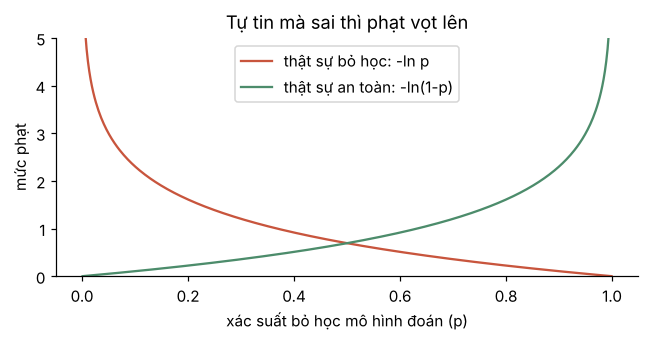

In [5]:
def sigmoid(z):
    """Hàm nén: số thực bất kỳ -> xác suất trong (0, 1). Viết kiểu ổn định để không tràn số."""
    z = np.clip(z, -500, 500)
    return np.where(z >= 0, 1 / (1 + np.exp(-z)), np.exp(z) / (1 + np.exp(z)))


def cross_entropy(p, y):
    """Mức phạt trung bình: -[ y ln p + (1-y) ln(1-p) ]"""
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))


print("sigmoid(-5), sigmoid(0), sigmoid(5) =", sigmoid(np.array([-5, 0, 5])).round(3))

# Bảng mức phạt: tự tin mà sai bị phạt rất nặng
bang = pd.DataFrame({"mô hình đoán P(bỏ học)": [0.99, 0.90, 0.50, 0.10, 0.01]})
bang["thật sự bỏ học: -ln p"] = -np.log(bang.iloc[:, 0])
bang["thật sự an toàn: -ln(1-p)"] = -np.log(1 - bang.iloc[:, 0])
display(bang.round(3))

p = np.linspace(0.001, 0.999, 400)
plt.figure(figsize=(6, 3.2))
plt.plot(p, -np.log(p), color="#C8553D", label="thật sự bỏ học: -ln p")
plt.plot(p, -np.log(1 - p), color="#4C8C6B", label="thật sự an toàn: -ln(1-p)")
plt.ylim(0, 5); plt.xlabel("xác suất bỏ học mô hình đoán (p)"); plt.ylabel("mức phạt"); plt.legend()
plt.title("Tự tin mà sai thì phạt vọt lên"); plt.tight_layout(); plt.show()

In [6]:
# Mức phạt của mô hình "tự lập" ở Bước 2 trên tập huấn luyện
p_tu_lap = sigmoid(Xtr @ w + b)
print("Cross-entropy của bộ trọng số tự lập:", round(cross_entropy(p_tu_lap, ytr), 4))
print("Cross-entropy khi luôn đoán 0,5 (không biết gì)  :", round(cross_entropy(np.full(len(ytr), 0.5), ytr), 4), "(= ln 2)")

Cross-entropy của bộ trọng số tự lập: 0.3429
Cross-entropy khi luôn đoán 0,5 (không biết gì)  : 0.6931 (= ln 2)


## Đọc kết quả
- Bảng phạt: đoán 0,99 là bỏ học mà thật ra an toàn bị phạt 4,6; đoán đúng thì chỉ 0,01. **Tự tin mà sai bị phạt gấp hơn 400 lần so với tự tin mà đúng.** Đó là tinh thần "nổ tan xác" của thầy.
- Mô hình "không biết gì" (luôn đoán 0,5) có mức phạt 0,693 = ln 2. Mô hình tốt phải thấp hơn nhiều con số này.
- Bộ trọng số tự lập của ta chỉ là một dự đoán đại khái. Việc *tìm bộ trọng số làm mức phạt nhỏ nhất* chính là việc "học", sang Bước 4.

## Thầy có thể hỏi
- *Vì sao dùng cross-entropy mà không dùng bình phương sai số?* Cross-entropy sinh ra từ ước lượng hợp lý cực đại của mô hình Bernoulli, phạt nặng sự tự tin sai, và (kết hợp với sigmoid) cho gradient rất gọn, ta sẽ thấy ở Bước 4.
- *Sigmoid có ý nghĩa gì?* Biến "mức nguy hiểm" tùy ý thành xác suất để đọc được và để cross-entropy dùng được.
- *Mức phạt -ln p có ý nghĩa gì?* Là độ "ngạc nhiên" của mô hình khi thấy kết cục thật. Càng ngạc nhiên càng bị phạt.